# ch04_3. CIFAR-10 기본 CNN 학습과 평가

## 개요

- Fashion-MNIST의 흑백 1채널 CNN을 RGB 3채널 CNN으로 확장합니다.
- `nn.Sequential`로 2계층 기본 CNN을 구성합니다.

## 공통 설정

데이터·모델·이미지 폴더 위치를 지정합니다.

In [1]:
from pathlib import Path

DATA_DIR = Path("data")
MODEL_DIR = Path("models")
PNG_DIR = Path("png")

DATA_DIR.mkdir(exist_ok=True)

MODEL_DIR.mkdir(exist_ok=True)
PNG_DIR.mkdir(exist_ok=True)

print("데이터 폴더:", DATA_DIR)
print("모델 폴더  :", MODEL_DIR)
print("이미지 폴더:", PNG_DIR)


데이터 폴더: data
모델 폴더  : models
이미지 폴더: png


## 공통 import

In [2]:
import copy
from pathlib import Path
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import matplotlib.pyplot as plt

### 1) 실행 장치 확인

:

```text
Fashion-MNIST
→ 흑백 1채널
→ 28×28
→ 비교적 단순한 배경
```

:

```text
CIFAR-10
→ RGB 3채널
→ 32×32
→ 다양한 물체·방향·배경
```

CNN의 학습 절차는 같습니다.
이번에 새롭게 확인할 내용은 **RGB 입력과 더 복잡한 이미지 분류**입니다.

```text
CIFAR-10 다운로드
→ RGB 채널별 정규화
→ 훈련 45,000개·검증 5,000개·테스트 10,000개
→ 기본 CNN 구성
→ Shape와 파라미터 확인
→ 30 Epoch 학습
→ 최고 검증 가중치 복원
→ 테스트 평가
→ 혼동행렬·클래스별 정확도
→ 대표 오답
→ Checkpoint 저장
```

In [3]:
RANDOM_SEED = 42

torch.manual_seed(RANDOM_SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("사용 장치:", device)

사용 장치: cuda


### 2) CIFAR-10 데이터 구성

CIFAR-10은 32×32 RGB 컬러 이미지 10종으로 구성됩니다.

```text
공식 훈련 데이터 50,000개
→ 학습 데이터 45,000개
→ 검증 데이터 5,000개

공식 테스트 데이터
→ 테스트 데이터 10,000개
```

| 번호 | 클래스 |
|---:|---|
| 0 | 비행기 |
| 1 | 자동차 |
| 2 | 새 |
| 3 | 고양이 |
| 4 | 사슴 |
| 5 | 개 |
| 6 | 개구리 |
| 7 | 말 |
| 8 | 배 |
| 9 | 트럭 |

In [4]:
BATCH_SIZE = 128

NUMBER_OF_EPOCHS = 30

LEARNING_RATE = 0.001

VALIDATION_SIZE = 5_000

class_names = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

class_names_ko = [
    "비행기",
    "자동차",
    "새",
    "고양이",
    "사슴",
    "개",
    "개구리",
    "말",
    "배",
    "트럭"
]

print("Batch Size:", BATCH_SIZE)

print("Epoch:", NUMBER_OF_EPOCHS)

print("Learning Rate:", LEARNING_RATE)

Batch Size: 128
Epoch: 30
Learning Rate: 0.001


### 3) 데이터 전처리 설정

RGB 채널은 서로 다른 픽셀 분포를 가집니다.

```text
원본 이미지
→ ToTensor
→ Red·Green·Blue 채널별 정규화
→ CNN 입력
```

사용할 평균과 표준편차:

```text
Mean = (0.4914, 0.4822, 0.4465)
Std = (0.2470, 0.2435, 0.2616)
```

기본 모델에서는 Data Augmentation(데이터 오그멘테이션, 데이터 증강)을 사용하지 않습니다.

In [5]:
CIFAR10_MEAN = (
    0.4914,
    0.4822,
    0.4465
)

CIFAR10_STD = (
    0.2470,
    0.2435,
    0.2616
)

transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize(
            mean=CIFAR10_MEAN,
            std=CIFAR10_STD
        )
    ]
)

### 4) DataLoader 준비

- 학습 데이터: `shuffle=True`
- 검증·테스트 데이터: `shuffle=False`
- 고정 Seed를 사용하여 같은 훈련·검증 분할을 만듭니다.

In [6]:
full_train_dataset = datasets.CIFAR10(
    root=str(DATA_DIR / "torchvision"),
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.CIFAR10(
    root=str(DATA_DIR / "torchvision"),
    train=False,
    download=True,
    transform=transform
)

train_size = (
    len(full_train_dataset)
    - VALIDATION_SIZE
)

split_generator = torch.Generator().manual_seed(
    RANDOM_SEED
)

train_dataset, validation_dataset = random_split(
    full_train_dataset,
    [train_size, VALIDATION_SIZE],
    generator=split_generator
)

loader_generator = torch.Generator().manual_seed(
    RANDOM_SEED
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=loader_generator
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

100.0%


### 5) DataLoader 준비

In [7]:
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("학습 데이터:", len(train_dataset))

print("검증 데이터:", len(validation_dataset))

print("테스트 데이터:", len(test_dataset))

학습 데이터: 45000
검증 데이터: 5000
테스트 데이터: 10000


### 6) Tensor 만들기와 구조 확인

정규화된 이미지는 화면에 표시할 때만 원래 범위에 가깝게 복원합니다.

```text
정규화된 Tensor
→ 표준편차 곱하기
→ 평균 더하기
→ 0~1 범위로 제한
```

In [8]:
def denormalize_image(image):
    mean = torch.tensor(
        CIFAR10_MEAN,
        dtype=image.dtype
    ).view(3, 1, 1)

    std = torch.tensor(
        CIFAR10_STD,
        dtype=image.dtype
    ).view(3, 1, 1)

    return (
        image.cpu() * std + mean
    ).clamp(0, 1)

### 7) 배치 데이터 확인

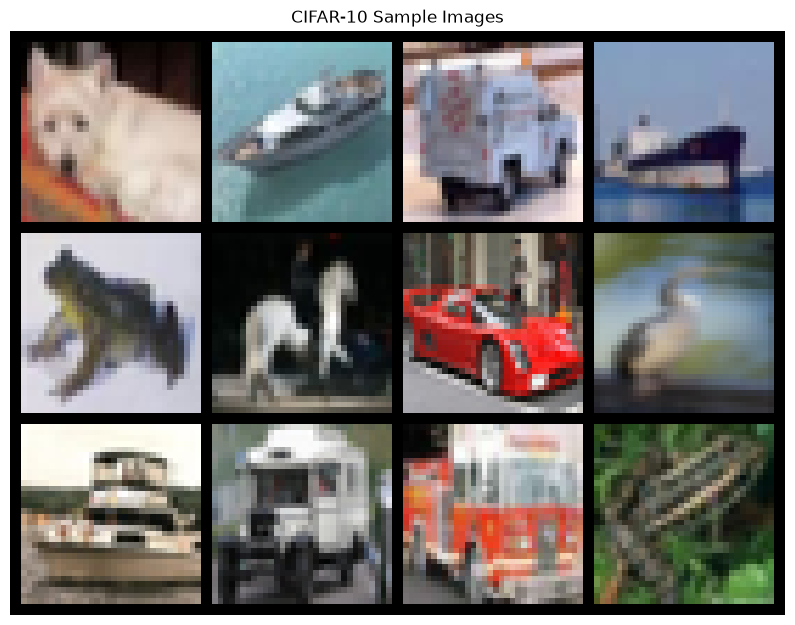

이미지 배치 Shape: torch.Size([128, 3, 32, 32])
정답 배치 Shape: torch.Size([128])

표시된 이미지의 실제 클래스


In [9]:
sample_images, sample_labels = next(
    iter(train_loader)
)

display_images = torch.stack(
    [
        denormalize_image(image)
        for image in sample_images[:12]
    ]
)

image_grid = make_grid(
    display_images,
    nrow=4,
    padding=2
)

plt.figure(figsize=(10, 8))

plt.imshow(
    image_grid.permute(1, 2, 0)
)

plt.title("CIFAR-10 Sample Images")

plt.axis("off")

plt.show()

print("이미지 배치 Shape:", sample_images.shape)

print("정답 배치 Shape:", sample_labels.shape)

print()

print("표시된 이미지의 실제 클래스")

### 8) 샘플 클래스 확인

In [10]:
for index in range(12):
    print(
        f"{index:>2d}: "
        f"{class_names_ko[sample_labels[index].item()]}"
    )

 0: 개
 1: 배
 2: 트럭
 3: 배
 4: 개구리
 5: 말
 6: 자동차
 7: 새
 8: 배
 9: 트럭
10: 트럭
11: 개구리


### 9) 결과 시각화

CIFAR-10 입력 Shape:

```text
[N, 3, 32, 32]
```

첫 번째 합성곱 필터는 Red·Green·Blue 세 채널을 동시에 처리합니다.

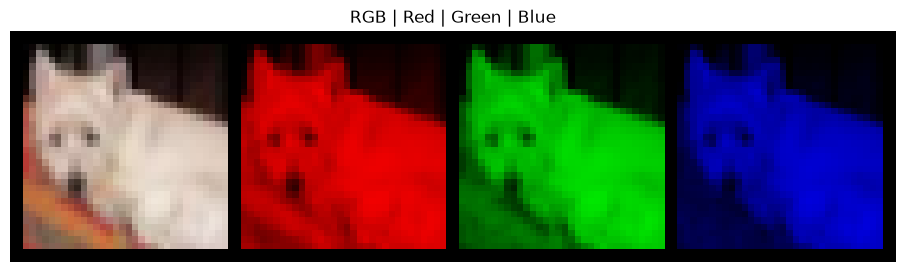

한 이미지 Shape: torch.Size([3, 32, 32])


In [11]:
rgb_image = denormalize_image(
    sample_images[0]
)

red_image = torch.zeros_like(rgb_image)

green_image = torch.zeros_like(rgb_image)

blue_image = torch.zeros_like(rgb_image)

red_image[0] = rgb_image[0]

green_image[1] = rgb_image[1]

blue_image[2] = rgb_image[2]

channel_grid = make_grid(
    torch.stack(
        [
            rgb_image,
            red_image,
            green_image,
            blue_image
        ]
    ),
    nrow=4,
    padding=2
)

plt.figure(figsize=(12, 3))

plt.imshow(
    channel_grid.permute(1, 2, 0)
)

plt.title("RGB | Red | Green | Blue")

plt.axis("off")

plt.show()

print("한 이미지 Shape:", rgb_image.shape)

### 10) 모델 구성

```text
입력 [N, 3, 32, 32]

→ Conv2d(3, 32)
→ ReLU
→ MaxPool2d
→ [N, 32, 16, 16]

→ Conv2d(32, 64)
→ ReLU
→ MaxPool2d
→ [N, 64, 8, 8]

→ Flatten
→ [N, 4096]

→ Linear(4096, 128)
→ ReLU
→ Linear(128, 10)
→ [N, 10]
```

이 모델을 Baseline(베이스라인, 기준 모델)으로 사용합니다.

다음 기능은 아직 사용하지 않습니다.

- 데이터 증강
- Batch Normalization(배치 노멀라이제이션)
- Dropout
- 깊은 CNN

In [12]:
def make_basic_cnn():
    return nn.Sequential(
        nn.Conv2d(
            3,
            32,
            kernel_size=3,
            padding=1
        ),
        nn.ReLU(),
        nn.MaxPool2d(
            kernel_size=2,
            stride=2
        ),

        nn.Conv2d(
            32,
            64,
            kernel_size=3,
            padding=1
        ),
        nn.ReLU(),
        nn.MaxPool2d(
            kernel_size=2,
            stride=2
        ),

        nn.Flatten(start_dim=1),
        nn.Linear(
            64 * 8 * 8,
            128
        ),
        nn.ReLU(),
        nn.Linear(
            128,
            10
        )
    )

### 11) 모델 구조 확인

In [13]:
torch.manual_seed(RANDOM_SEED)

model = make_basic_cnn().to(device)

print(model)

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=4096, out_features=128, bias=True)
  (8): ReLU()
  (9): Linear(in_features=128, out_features=10, bias=True)
)


### 12) 계층별 Shape와 파라미터 수

RGB Batch가 예상한 Shape로 통과하는지만 확인합니다.

In [14]:
layer_names = [
    "Conv1",
    "ReLU1",
    "Pool1",
    "Conv2",
    "ReLU2",
    "Pool2",
    "Flatten",
    "Linear1",
    "ReLU3",
    "Linear2"
]

features = sample_images[:4].to(device)

print("Input   :", features.shape)

for layer_name, layer in zip(
    layer_names,
    model
):
    features = layer(features)

    print(
        f"{layer_name:<8}:",
        features.shape
    )

parameter_count = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print()

print(
    "학습 파라미터 수:",
    f"{parameter_count:,}개"
)

Input   : torch.Size([4, 3, 32, 32])
Conv1   : torch.Size([4, 32, 32, 32])
ReLU1   : torch.Size([4, 32, 32, 32])
Pool1   : torch.Size([4, 32, 16, 16])
Conv2   : torch.Size([4, 64, 16, 16])
ReLU2   : torch.Size([4, 64, 16, 16])
Pool2   : torch.Size([4, 64, 8, 8])
Flatten : torch.Size([4, 4096])
Linear1 : torch.Size([4, 128])
ReLU3   : torch.Size([4, 128])
Linear2 : torch.Size([4, 10])

학습 파라미터 수: 545,098개


### 13) Loss 함수와 Optimizer 설정

- 손실함수: `nn.CrossEntropyLoss()`
- Optimizer(옵티마이저, 가중치 갱신 방법): Adam(아담)
- 학습률: `0.001`

모델의 마지막 출력은 Softmax를 적용하지 않은 로짓입니다.

In [15]:
loss_function = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

### 14) 학습 함수 정의

학습 함수는 동일한 구조를 사용하며, CNN 내부만 RGB 입력용으로 구성합니다.

In [16]:
def train_one_epoch(
    model,
    data_loader
):
    model.train()

    loss_sum = 0.0
    correct = 0
    total = 0

    for images, labels in data_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(images)

        loss = loss_function(
            logits,
            labels
        )

        loss.backward()
        optimizer.step()

        predictions = logits.argmax(
            dim=1
        )

        loss_sum += (
            loss.item()
            * images.size(0)
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    return (
        loss_sum / total,
        correct / total
    )

### 15) 평가 함수 정의

In [17]:
def evaluate_model(
    model,
    data_loader
):
    model.eval()

    loss_sum = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)

            loss = loss_function(
                logits,
                labels
            )

            predictions = logits.argmax(
                dim=1
            )

            loss_sum += (
                loss.item()
                * images.size(0)
            )

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

    return (
        loss_sum / total,
        correct / total
    )

### 16) 학습 기록과 최적 모델 준비

모델 선택 기준:

1. 검증 정확도가 더 높은 Epoch
2. 정확도가 같으면 검증 손실이 더 낮은 Epoch

테스트 데이터는 모델 선택에 사용하지 않습니다.

In [18]:
history = {
    "train_loss": [],
    "train_accuracy": [],
    "validation_loss": [],
    "validation_accuracy": []
}

best_validation_accuracy = -1.0

best_validation_loss = float("inf")

best_epoch = 0

best_model_state = copy.deepcopy(
    model.state_dict()
)

### 17) 모델 학습

In [19]:
for epoch in range(
    1,
    NUMBER_OF_EPOCHS + 1
):
    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader
    )

    validation_loss, validation_accuracy = (
        evaluate_model(
            model,
            validation_loader
        )
    )

    history["train_loss"].append(
        train_loss
    )

    history["train_accuracy"].append(
        train_accuracy
    )

    history["validation_loss"].append(
        validation_loss
    )

    history["validation_accuracy"].append(
        validation_accuracy
    )

    is_better = (
        validation_accuracy
        > best_validation_accuracy
        or (
            validation_accuracy
            == best_validation_accuracy
            and validation_loss
            < best_validation_loss
        )
    )

    if is_better:
        best_validation_accuracy = (
            validation_accuracy
        )

        best_validation_loss = (
            validation_loss
        )

        best_epoch = epoch

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

    print(
        f"Epoch {epoch:>2d}/{NUMBER_OF_EPOCHS} | "
        f"Train Loss {train_loss:.4f} | "
        f"Train Accuracy {train_accuracy:.4f} | "
        f"Validation Loss {validation_loss:.4f} | "
        f"Validation Accuracy {validation_accuracy:.4f}"
    )

Epoch  1/30 | Train Loss 1.4212 | Train Accuracy 0.4909 | Validation Loss 1.1288 | Validation Accuracy 0.6012
Epoch  2/30 | Train Loss 1.0300 | Train Accuracy 0.6378 | Validation Loss 0.9679 | Validation Accuracy 0.6558
Epoch  3/30 | Train Loss 0.8683 | Train Accuracy 0.6973 | Validation Loss 0.9246 | Validation Accuracy 0.6720
Epoch  4/30 | Train Loss 0.7671 | Train Accuracy 0.7330 | Validation Loss 0.8541 | Validation Accuracy 0.6986
Epoch  5/30 | Train Loss 0.6721 | Train Accuracy 0.7665 | Validation Loss 0.8592 | Validation Accuracy 0.6994
Epoch  6/30 | Train Loss 0.5910 | Train Accuracy 0.7924 | Validation Loss 0.8312 | Validation Accuracy 0.7114
Epoch  7/30 | Train Loss 0.5127 | Train Accuracy 0.8226 | Validation Loss 0.8253 | Validation Accuracy 0.7186
Epoch  8/30 | Train Loss 0.4436 | Train Accuracy 0.8473 | Validation Loss 0.8876 | Validation Accuracy 0.7220
Epoch  9/30 | Train Loss 0.3723 | Train Accuracy 0.8712 | Validation Loss 0.9407 | Validation Accuracy 0.7196
Epoch 10/3

### 18) 학습 기록과 최적 모델 준비

In [20]:
model.load_state_dict(
    best_model_state
)

print()

print("최고 검증 Epoch:", best_epoch)

print(
    "최고 검증 정확도:",
    f"{best_validation_accuracy:.4f}"
)


최고 검증 Epoch: 11
최고 검증 정확도: 0.7236


### 19) 학습 Loss 시각화

훈련 손실과 검증 손실이 함께 감소하는지 확인합니다.

검증 손실이 다시 증가하면 과적합 가능성이 있습니다.

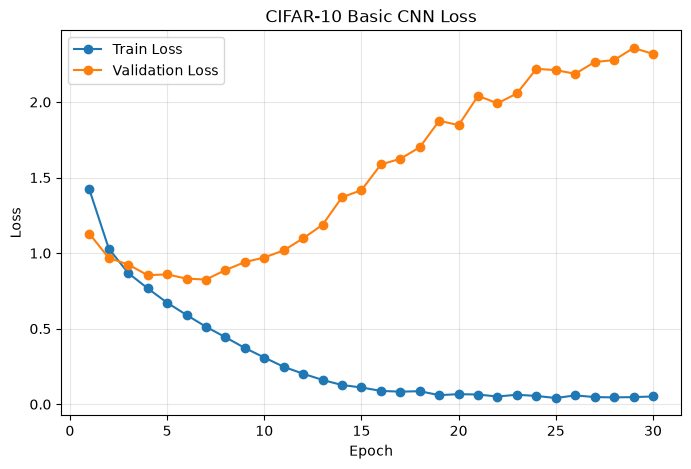

In [21]:
epoch_numbers = range(
    1,
    NUMBER_OF_EPOCHS + 1
)

plt.figure(figsize=(8, 5))

plt.plot(
    epoch_numbers,
    history["train_loss"],
    marker="o",
    label="Train Loss"
)

plt.plot(
    epoch_numbers,
    history["validation_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("CIFAR-10 Basic CNN Loss")

plt.grid(alpha=0.3)

plt.legend()

plt.show()

### 20) 학습 정확도 시각화

훈련 정확도와 검증 정확도의 차이가 커지는지 확인합니다.

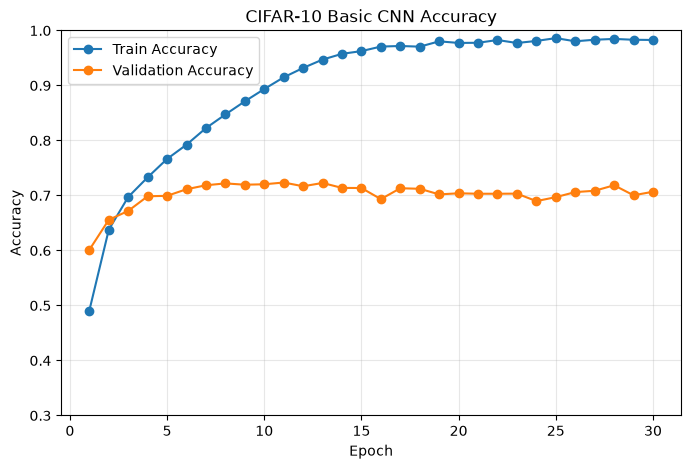

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(
    epoch_numbers,
    history["train_accuracy"],
    marker="o",
    label="Train Accuracy"
)

plt.plot(
    epoch_numbers,
    history["validation_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.title("CIFAR-10 Basic CNN Accuracy")

plt.ylim(0.3, 1.0)

plt.grid(alpha=0.3)

plt.legend()

plt.show()

### 21) 테스트 성능 확인

검증 데이터로 선택한 최고 가중치 하나만 테스트 데이터로 평가합니다.

In [23]:
test_loss, test_accuracy = evaluate_model(
    model,
    test_loader
)

print(f"테스트 손실: {test_loss:.4f}")

print(f"테스트 정확도: {test_accuracy:.4f}")

print(
    f"맞힌 이미지 수: "
    f"{int(test_accuracy * len(test_dataset)):,}"
    f" / {len(test_dataset):,}"
)

테스트 손실: 1.1079
테스트 정확도: 0.7109
맞힌 이미지 수: 7,109 / 10,000


### 22) 데이터 구조 확인

이후 분석에서 모델을 반복 실행하지 않도록 다음 결과를 한 번에 모읍니다.

- 이미지
- 실제 클래스
- 예측 클래스
- 예측 확률

In [24]:
image_batches = []

label_batches = []

logit_batches = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        logits = model(
            images.to(device)
        ).cpu()

        image_batches.append(images)
        label_batches.append(labels)
        logit_batches.append(logits)

all_images = torch.cat(
    image_batches
)

all_labels = torch.cat(
    label_batches
)

all_logits = torch.cat(
    logit_batches
)

all_probabilities = torch.softmax(
    all_logits,
    dim=1
)

all_confidences, all_predictions = (
    all_probabilities.max(dim=1)
)

print("전체 이미지 Shape:", all_images.shape)

print("전체 예측 Shape:", all_predictions.shape)

전체 이미지 Shape: torch.Size([10000, 3, 32, 32])
전체 예측 Shape: torch.Size([10000])


### 23) Confusion Matrix 준비

```text
행: 실제 클래스
열: 예측 클래스
대각선: 올바른 예측
대각선 밖: 잘못된 예측
```

번호와 클래스의 대응은 앞의 클래스 표를 사용합니다.

In [25]:
confusion_matrix = torch.zeros(
    10,
    10,
    dtype=torch.int64
)

### 24) Confusion Matrix 계산

In [26]:
for actual, predicted in zip(
    all_labels,
    all_predictions
):
    confusion_matrix[
        actual,
        predicted
    ] += 1

### 25) Confusion Matrix 시각화

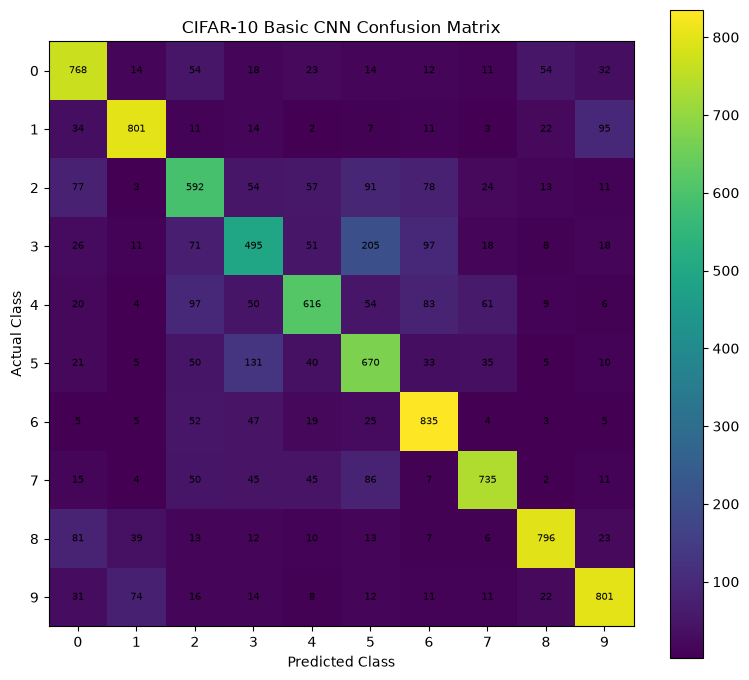

In [27]:
plt.figure(figsize=(8, 7))

plt.imshow(
    confusion_matrix.numpy()
)

plt.xticks(range(10))

plt.yticks(range(10))

plt.xlabel("Predicted Class")

plt.ylabel("Actual Class")

plt.title("CIFAR-10 Basic CNN Confusion Matrix")

for row in range(10):
    for column in range(10):
        plt.text(
            column,
            row,
            int(confusion_matrix[row, column]),
            ha="center",
            va="center",
            fontsize=7
        )

plt.colorbar()

plt.tight_layout()

plt.show()

### 26) 모델 구성

전체 정확도만으로는 어떤 물체에 약한지 알기 어렵습니다.

```text
클래스별 정확도
→ 해당 클래스를 맞힌 개수
÷ 해당 클래스의 전체 개수
```

In [28]:
class_correct = confusion_matrix.diag()

class_total = confusion_matrix.sum(
    dim=1
)

class_accuracy = (
    class_correct.float()
    / class_total
)

for class_index in range(10):
    print(
        f"{class_index}: "
        f"{class_names_ko[class_index]:<4} | "
        f"{class_accuracy[class_index].item():.4f}"
    )

lowest_class = torch.argmin(
    class_accuracy
).item()

print()

print(
    "가장 낮은 정확도의 클래스:",
    class_names_ko[lowest_class]
)

0: 비행기  | 0.7680
1: 자동차  | 0.8010
2: 새    | 0.5920
3: 고양이  | 0.4950
4: 사슴   | 0.6160
5: 개    | 0.6700
6: 개구리  | 0.8350
7: 말    | 0.7350
8: 배    | 0.7960
9: 트럭   | 0.8010

가장 낮은 정확도의 클래스: 고양이


### 27) 모델 구성

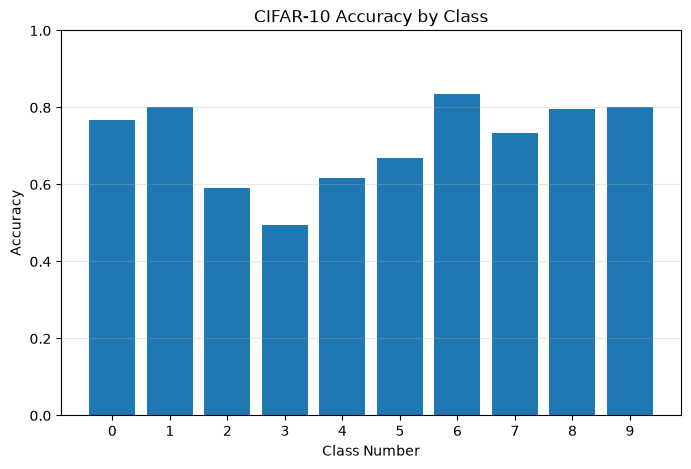

In [29]:
plt.figure(figsize=(8, 5))

plt.bar(
    range(10),
    class_accuracy.numpy()
)

plt.xticks(range(10))

plt.ylim(0.0, 1.0)

plt.xlabel("Class Number")

plt.ylabel("Accuracy")

plt.title("CIFAR-10 Accuracy by Class")

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

### 28) 주요 오분류 확인

혼동행렬의 대각선을 제외하고 가장 큰 값을 찾습니다.

방향을 구분해야 합니다.

```text
실제 고양이 → 예측 개
```

위 관계와 `실제 개 → 예측 고양이`는 서로 다른 오류입니다.

In [30]:
wrong_confusion = confusion_matrix.clone()

wrong_confusion.fill_diagonal_(0)

flat_index = wrong_confusion.argmax().item()

confused_actual = (
    flat_index // 10
)

confused_predicted = (
    flat_index % 10
)

confused_count = wrong_confusion[
    confused_actual,
    confused_predicted
].item()

print(
    f"실제 {class_names_ko[confused_actual]} "
    f"→ 예측 {class_names_ko[confused_predicted]}: "
    f"{confused_count}개"
)

실제 고양이 → 예측 개: 205개


### 29) 오분류 데이터 확인

대표 오답 12개를 확인합니다.

- `A`: 실제 클래스
- `P`: 예측 클래스
- `C`: 예측 확률

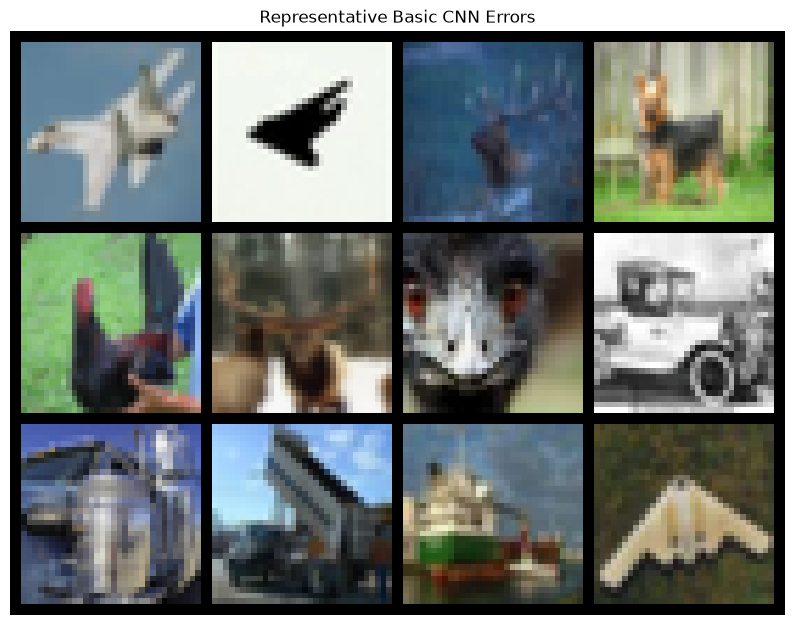

대표 오답


In [31]:
wrong_mask = (
    all_predictions != all_labels
)

wrong_images = all_images[
    wrong_mask
]

wrong_labels = all_labels[
    wrong_mask
]

wrong_predictions = all_predictions[
    wrong_mask
]

wrong_confidences = all_confidences[
    wrong_mask
]

number_of_examples = min(
    12,
    len(wrong_images)
)

display_wrong_images = torch.stack(
    [
        denormalize_image(image)
        for image in wrong_images[
            :number_of_examples
        ]
    ]
)

wrong_grid = make_grid(
    display_wrong_images,
    nrow=4,
    padding=2
)

plt.figure(figsize=(10, 8))

plt.imshow(
    wrong_grid.permute(1, 2, 0)
)

plt.title("Representative Basic CNN Errors")

plt.axis("off")

plt.show()

print("대표 오답")

### 30) 오분류 데이터 확인

In [32]:
for index in range(number_of_examples):
    actual_name = class_names_ko[
        wrong_labels[index].item()
    ]

    predicted_name = class_names_ko[
        wrong_predictions[index].item()
    ]

    print(
        f"{index:>2d} | "
        f"A:{actual_name:<4} | "
        f"P:{predicted_name:<4} | "
        f"C:{wrong_confidences[index].item():.3f}"
    )

 0 | A:비행기  | P:개    | C:0.543
 1 | A:비행기  | P:새    | C:0.816
 2 | A:사슴   | P:비행기  | C:0.678
 3 | A:개    | P:사슴   | C:0.990
 4 | A:새    | P:사슴   | C:0.649
 5 | A:사슴   | P:새    | C:0.829
 6 | A:새    | P:고양이  | C:0.619
 7 | A:자동차  | P:트럭   | C:0.756
 8 | A:트럭   | P:고양이  | C:0.769
 9 | A:트럭   | P:말    | C:0.530
10 | A:배    | P:비행기  | C:0.782
11 | A:비행기  | P:개구리  | C:0.760


### 31) 모델 저장

Checkpoint에는 다음 정보를 함께 저장합니다.

- 기본 CNN 가중치
- 합성곱 채널 수
- 은닉층 크기
- 정규화 평균과 표준편차
- 클래스 이름
- 최고 검증 성능
- 테스트 성능

저장한 모델은 개선 CNN과의 성능 비교에 사용합니다.

In [33]:
checkpoint_path = MODEL_DIR / "ch04_3_best_cifar10_basic_cnn.pt"

checkpoint = {
    "model_name": "CIFAR-10 Basic CNN",
    "model_state_dict": model.state_dict(),
    "input_channels": 3,
    "feature_channels": [32, 64],
    "hidden_size": 128,
    "image_size": [3, 32, 32],
    "number_of_classes": 10,
    "class_names": class_names,
    "class_names_ko": class_names_ko,
    "normalization_mean": list(CIFAR10_MEAN),
    "normalization_std": list(CIFAR10_STD),
    "best_epoch": best_epoch,
    "validation_loss": best_validation_loss,
    "validation_accuracy": best_validation_accuracy,
    "test_loss": test_loss,
    "test_accuracy": test_accuracy
}

torch.save(
    checkpoint,
    checkpoint_path
)

loaded_checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

restored_model = make_basic_cnn()

restored_model.load_state_dict(
    loaded_checkpoint[
        "model_state_dict"
    ]
)

restored_model.eval()

print("저장 파일:", checkpoint_path)

print(
    "저장된 검증 정확도:",
    f"{loaded_checkpoint['validation_accuracy']:.4f}"
)

저장 파일: models/ch05_3_best_cifar10_basic_cnn.pt
저장된 검증 정확도: 0.7236


### 32) 테스트 성능 확인

In [34]:
print(
    "저장된 테스트 정확도:",
    f"{loaded_checkpoint['test_accuracy']:.4f}"
)

저장된 테스트 정확도: 0.7109
